# Linear Models in Classification 2

## Introduction

In this lab, we're going to look at linear models in classification. In lecture, we considered three methods of fitting linear decision boundaries: fit by __regression__, fit by __estimating labels by a Gaussian distributions__, and fit by __logistic regression__. 

 

We will then apply multilabel classification techniques to the MNIST handwriting dataset. The MNIST dataset contains pictures of hand written digits, and attempts to classify them. In MNIST, the feature space is high dimensional while the label space is relatively low, and will serve as a bench mark for many of our later machine learning techniques. 


 

# Multilabel Classification

Now that we have some classification and visualization tools under our belt, lets turn to a high dimensional problem: Using linear methods to classify the MNIST (Mixed National Institute of Standards and Technology) dataset. MNIST is essentially the "Hello World" of visual machine learning.

<table>
    <tr><td>
        <img src="https://upload.wikimedia.org/wikipedia/commons/2/27/MnistExamples.png" width=300px>
        </td>
        </td><td width=20px>
            $$\Rightarrow$$
        </td>
        <td width=40px>
        <table><tr><td>0</td></tr><tr><td>1</td></tr><tr><td>2</td></tr><tr><td>3</td></tr>
        <tr><td>4</td></tr><tr><td>5</td></tr><tr><td>6</td></tr><tr><td>7</td></tr><tr><td>8</td></tr>
            <tr><td>9</td></tr>
        </table>
        </td>
    </tr>
</table>

Our goal with MNIST will be to correctly predict the number for picture. 

It's worth taking a look at MNIST's home: http://yann.lecun.com/exdb/mnist/, where they have the current best benchmarks on the dataset (of course reproducibility is required). 

Alternatively, you can download it from Kaggle https://www.kaggle.com/c/digit-recognizer/data (if you cannot open .gz files) or if you are on Google colab, use 

`from keras.datasets import mnist`

`(x_train, y_train), (x_test, y_test) = mnist.load_data()`

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
#from keras.datasets import mnist  
#(X_train, y_train), (X_test, y_test) = mnist.load_data()

# If your files have been saved locally:

MNIST_train = pd.read_csv("data/train.csv")
MNIST_test = pd.read_csv("data/train.csv")

Each row of the data set consists of a label, and list of 784 pixel values (either 0 to 255), forming $28\times 28$ pictures . If you downloaded the data locally, you may need to split into training features and labels and recast the data as a numpy array to make it easier to call. 

In [3]:
y_train = np.array(MNIST_train["label"])
X_train = np.array(MNIST_train.drop(columns=["label"]))

y_test = np.array(MNIST_test["label"])
X_test = np.array(MNIST_test.drop(columns=["label"]))

In [4]:
print(X_train.shape)
print(X_test.shape)
#X_train

(42000, 784)
(42000, 784)


Visualizing one of the pictures is simple enough, we just use `.reshape(28,28)` on a row of `X_train` and then use `plt.imshow` to display the pixels of the matrix as black and white. 

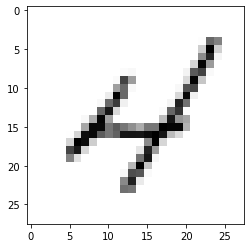

In [5]:
plt.imshow(X_train[700].reshape(28,28), cmap='Greys')

This looks like a 4, and that is what the label tells us:

In [6]:
y_train[700]

4

As one last step before we get started lets shuffle the data set to makes sure we're not picking up any information from the order. To do this we use `numpy.permutation` to generate a permutation of the index:

In [7]:
shuffle_index = np.random.permutation(42000)
X_train = X_train[shuffle_index]
y_train = y_train[shuffle_index]

## Some visualizations

It's hard to visualize high dimensional data. The visualization of high dimensional data is a whole lab in and of itself, but we can extract some interesting information (or at least some clarifying information!). 

First, lets find the "average" examples of each number:

(-0.5, 27.5, 27.5, -0.5)

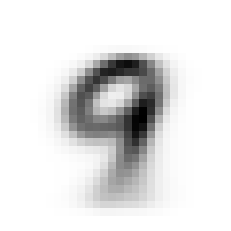

In [8]:
plt.imshow(X_train[y_train == 9].mean(0).reshape(28,28), cmap='Greys')

plt.axis('off')

Looping through the possible labels, we can construct a grid of images

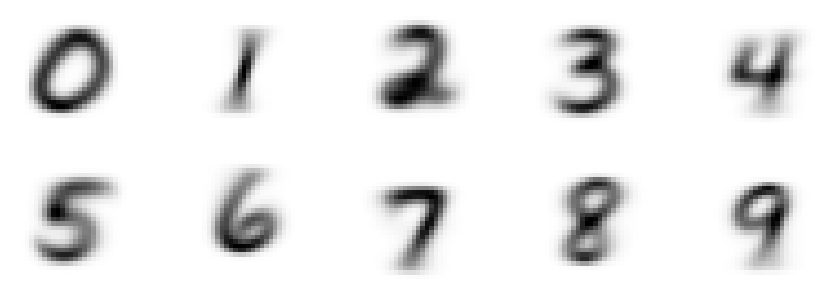

In [9]:
f, axes = plt.subplots(2,5,figsize=(15,5))

axes = axes.reshape(-1)

for i in range(0,10):
    axes[i].imshow(X_train[y_train == i].mean(0).reshape(28,28), cmap='Greys')
    axes[i].axis('off')

We can also form the pixel by pixel scatter plot, just to see if there is any structure here. We'll light up two adjacent pixels in the very middle: on the pixels 14 and 15 on row 14:

In [10]:
X_train[0:1000].reshape(-1, 28*28).shape

(1000, 784)

## Testing Our Classifiers: Logistic Regression

Lets start by trying to fit using logistic regression. There is nothing new that we need to do, the regression functions treat a large amount of data the same way as they treat a small amount of data. With logistic regression we don't even need to worry about one-hot encoding the labels. 

In [11]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(solver='lbfgs', max_iter=100)
clf.fit(X_train[0:1000].reshape(-1, 28*28),y_train[0:1000])
print("Logistic Regression Score: %.3f"%clf.score(X_test.reshape(-1, 28*28),y_test))

/usr/local/anaconda3/lib/python3.8/site-packages/sklearn/linear_model/_logistic.py:763: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Score: 0.863


This is quite good, so on average we're only missclassifying 15% pictures. Given that there is only one correct label and 10 incorrect ones this is a decent result. 

Remember as well that we have created a real predictor. For example, we can try to predict the 6001'st element of the MNIST data set:

In [12]:
print(clf.predict(X_test[6000].reshape(1,-1)))
print(y_test[6000])
print(clf.predict_proba(X_test[6000].reshape(1,-1)))

[1]
1
[[3.11727504e-25 1.00000000e+00 5.98851856e-16 7.28667176e-12
  1.02209703e-20 4.02279944e-20 2.29000602e-17 4.13170738e-15
  1.24319910e-13 2.87487412e-12]]


### New predictions

Try something yourself: Using MS paint or another program, create a $28\times 28$ picture with a black background and draw a which number on it. Save the picture as a bitmap in the same directory as the notebook. 

We can load this picture in with `plt.imread("picname.bmp")` and use `plt.imshow` to display it.

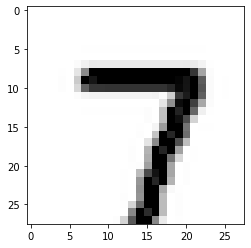

In [13]:
im = plt.imread("data/testpic.png")
plt.imshow(im,cmap='Greys')

If you look at the shape of the file, you'll see that it is `im.shape = (28,28,4)`. That means it has 4 channels: Red, Green, Blue and Alpha or RGBA. We've been fitting one channel black and white pictures, so to predict you must extract a single channel of data and reshape it from a matrix into a vector. If the picture is black and white the Red, Green and Blue channels will all contain the same information so we can just extract the zero'th channel.

In [14]:
im.shape

(28, 28, 4)

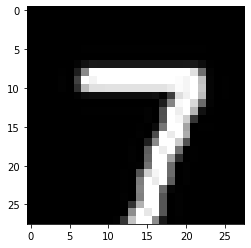

In [15]:
plt.imshow(im[:,:,0],cmap='Greys')

In addition, looking at `im[:,:,0]` we find that while `X_train` has data stored between 0 and 255, `im[:,:,0]` has the background as 1 and the foreground as 0. We need to rescale `im[:,:,0]` to be on the same order as the classifier.

In [16]:
im[:,:,0]

array([[1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        ],
       [1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        ],
       [1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.        , 1.        , 1.        , 1.        ,
        1.        , 1.    

In [17]:
mypic = 255*(1-im[:,:,0].reshape(1,-1))
print(clf.predict(mypic))
print(clf.predict_proba(mypic))

[7]
[[6.67982232e-18 5.99006725e-31 2.65040354e-17 3.73813940e-09
  2.35668676e-24 6.52906637e-25 3.31027314e-29 9.99999996e-01
  7.96486877e-17 3.06327326e-18]]


How did it do? If it's drastically off make sure you're picture is black on white, not white on black. 

## Testing Our Classifiers: LDA and QDA

Lets now compare these to the results for the quadratic and linear discriminant classifiers. First, you should notice that they run significantly faster than regression, and in fact we can crank up the number of training samples quite high. As expected, the more training data points we use the better our testing results are, but although that number shoots upward between 100 and 1000 data points, the rate of change tapers off as we pass 10,000 data points. 

In [18]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

## Liner Regression vis Linear Discriminant Analysis
lda = LinearDiscriminantAnalysis(store_covariance=True)
lda.fit(X_train[0:20000].reshape(-1,28*28), y_train[0:20000])
print("LDA Score: %.3f"%lda.score(X_test.reshape(-1,28*28),y_test))


LDA Score: 0.870


In [19]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

## Quadratic Discriminant Analysis
qda = QuadraticDiscriminantAnalysis(store_covariance=True)
qda.fit(X_train[0:10000].reshape(-1,28*28), y_train[0:10000])
print("QDA Score: %.3f"%qda.score(X_test.reshape(-1,28*28),y_test))

/usr/local/anaconda3/lib/python3.8/site-packages/sklearn/discriminant_analysis.py:808: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


QDA Score: 0.679


How does each of our classifiers do fitting our handwritten digit?

In [20]:
print("Logistic:",clf.predict(mypic))
print("Linear:",lda.predict(mypic))
print("Quadratic:",qda.predict(mypic))

Logistic: [7]
Linear: [7]
Quadratic: [7]


# Linear Regression

Finally, we will use straight linear regression. Recall our pipeline for linear regression:

* Convert the y values to a one-hot vector.
* Fit using linear regression.
* Predict using argmax

You might be surprised to see how much data we can squeeze through the standard linear classifier. You may even be able to train on the whole data set without any slowdown depending on your processor. 

In [21]:
from sklearn.linear_model import LinearRegression
N = 40000

y_train_OH = pd.get_dummies(y_train)
y_test_OH = pd.get_dummies(y_test)

lr = LinearRegression()
lr.fit(X_train[0:N].reshape(-1,28*28),y_train_OH[0:N])

print("The r^2 score on the training data is %.3f"%(lr.score(X_test.reshape(-1,28*28),y_test_OH)))

The r^2 score on the training data is -10514188594.548


How do we understand the score of this model? Is it just completely missclassifying the test data? Lets use `np.argmax` to predict the score on the first image in the training set. Rather annoyingly, we must use

`X_test[0].reshape(1, -1)`

to reshape the vector into a row vector since numpy returns single vectors as column vectors by default. But then, we're used to all vectors being column vectors unless otherwise stated!

In [22]:
pred = lr.predict(X_test[0].reshape(1, -1))
print(pred)

[[-0.02696543  0.64612002  0.0925896   0.03322305  0.10717257  0.13034399
  -0.10412568 -0.02058124  0.16278852 -0.01914911]]


We've return the linear predictors for each label, we will use `np.argmax` to return the position of the larges $\hat{f}_k$. Although by looking we can see it is 1, (remember the indexing starts from 0). We also check the true value.

In [23]:
print("Our Prediction:", np.argmax(pred))
print("True Value:", y_test[0])

Our Prediction: 1
True Value: 1


So it got the first one correct, what about the first five? Again, we can use `np.argmax`, although we need to specify that we're taking argmax for down the columns by specifying `axis=1`.

In [24]:
print("First Five Predictions:", np.argmax(lr.predict(X_test[0:5].reshape(-1,28*28)), axis=1))
print("First Five True Labels:", y_test[0:5])

First Five Predictions: [1 0 1 4 0]
First Five True Labels: [1 0 1 4 0]


Our predictor actually seems to be doing quite well, so what's going on? The answer of course is that it's returning the r^2 score, which is generally going to be horrible on a classification task. A better measure is to use the mean accuracy that the logistic regression, LDA and QDA classes used. Sci-kit learn has build in scores for most loss functions. 

Loading `accuracy_score` from `sklearn.metrics`, we predict on whole test set:

In [25]:
from sklearn.metrics import accuracy_score

y_predict = np.argmax(lr.predict(X_test.reshape(-1,28*28)),axis=1)

acc = accuracy_score(y_test, y_predict)
print("The accuracy score on the training data is %.3f"%(acc))

The accuracy score on the training data is 0.860


With enough data this is comparable to logistic regression.

## Confusion Matrix 

The mean accuracy is a useful measure of success, but it doesn't give us any granular information. For example, with a mean accuracy of 15% we could be in any of the following scenarios:

* For each digit, there's a 15% chance it will be misclassified.
* There's an equal split of data among all digits. However, 9's are always misclassified as 4's and 0's are misclassified half the time as 8's. 
* There's an equal split of data among all digits. However, 9's are always misclassified and 0's are misclassified 50% of the time, but it's always as something random.
* 85% of the data is 1's and the classifier is just classifying everything as 1. 
* Others?

This leads to the idea of __precision__ vs __recall__. For a label $k$, let $Tp_k$ be the number of __true positives__, that is the number of items correctly guessed to have label $k$. Let $Fp_k$ be the number of __false positives__, that is the number of items incorrectly guessed to have label $k$.

The __precision__ is 

$$
\textbf{Precision}_k = \frac{Tp_k}{Tp_k + Fp_k}\,,
$$

the proportion items we predicted to be labeled $k$ that actually were. Let $Fn_k$ be the number of __false negatives__, the is the number of items whose true label was $k$ that were incorrectly labeled. The __recall__ is

$$
\textbf{Recall}_k = \frac{Tp_k}{Tp_k + Fn_k}\,,
$$

the proportion of items whose true label is $k$ that are labeled correctly. 

These concepts can be collected into a __Confusion Matrix__. The confusion matrix summarizes how our predictor labeled test data vs the true labeling. 

We can import the confusion using `from sklearn.metrics import confusion_matrix`. We will then use our linear predictor to predict the labels on the test set, and use `confusion_matrix(y_true,y_predict)` to get a breakdown of how the data is misclassified. The true labeling is along the vertical axis and the guessed labeling is the horizontal. 

https://en.wikipedia.org/wiki/Confusion_matrix

In [26]:
from sklearn.metrics import confusion_matrix

y_predict = np.argmax(lr.predict(X_test.reshape(-1,28*28)),axis=1)

conf_mx = confusion_matrix(y_test, y_predict)
conf_mx

array([[3961,    5,   14,   12,   17,   32,   48,    2,   37,    4],
       [   1, 4560,   23,   10,   14,   13,   13,    5,   40,    5],
       [  69,  169, 3365,  101,   79,    9,  165,   67,  136,   17],
       [  24,  112,  136, 3673,   24,   96,   36,   76,   93,   81],
       [   7,   76,   31,    4, 3635,   39,   27,   14,   33,  206],
       [ 117,   77,   19,  311,   74, 2788,  132,   29,  160,   88],
       [  83,   48,   36,    0,   53,   63, 3830,    0,   24,    0],
       [  36,  136,   33,   28,  110,    6,    4, 3814,    7,  227],
       [  38,  316,   35,  164,   71,  149,   46,   13, 3129,  102],
       [  49,   41,    8,   87,  278,    9,    2,  320,   32, 3362]])

To compare the number of missclassifications, lets normalize the rows by dividing by the total number of each true label. We can then remove the diagonal and plot a heat map to see where things are getting misclassified. 

<AxesSubplot:>

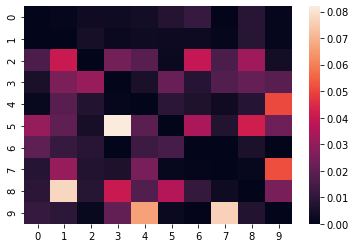

In [27]:
row_sum = conf_mx.sum(axis=1, keepdims=True)
nconf_mx = conf_mx/row_sum
np.fill_diagonal(nconf_mx,0)

sns.heatmap(nconf_mx)

So 9's are getting misclassified as 7's, 5's are getting misclassified as 3's and 8's as 1's.  Analyzing the confusion matrix can often tell you what's going right and wrong with your classification. It can also help to look at the individual mistakes. Let's get the index of training sets that contain 5's being misclassified as 3's:

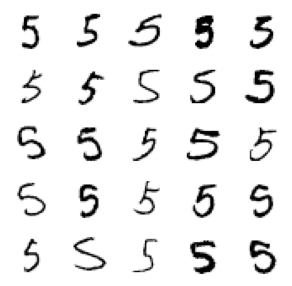

In [28]:
ft = (y_test == 5)&(y_predict == 3)

f, axes = plt.subplots(5,5,figsize=(5,5))
axes = axes.reshape(-1)

bads = X_test[ft][0:25]

for i in range(0,25):
    axes[i].imshow(bads[i].reshape(28,28),cmap="Greys")
    axes[i].axis('off')

Some of these seem like they should have been correctly classified, but some (like the top right corner) a human would have trouble classifying. That represents a sort of practical upper bound, there are many problems on which 100% accuracy is out of reach. 